## Assignment 8

#### Q1.  Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.). 

##### 1. Convert text to lowercase and remove punctua on using re. 2. Tokenize the text into words and sentences. 3. Split using split() and word_tokenize() and compare how Python split and NLTK’s word_tokenize() differ. 4. Remove stopwords (using NLTK's stopwords list). 5. Display word frequency distribu on (excluding stopwords).

[nltk_data] Error loading punkt: <urlopen error [WinError 10054] An
[nltk_data]     existing connection was forcibly closed by the remote
[nltk_data]     host>
[nltk_data] Error loading punkt_tab: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>
[nltk_data] Error loading stopwords: <urlopen error [WinError 10054]
[nltk_data]     An existing connection was forcibly closed by the
[nltk_data]     remote host>


Cleaned text:
 technology has quietly become the backbone of modern life shaping how we work learn and connect with one another artificial intelligence in particular is transforming industries by automating repetitive tasks and uncovering patterns that humans often miss programmers write code that turns abstract ideas into tools used by millions of people every day its amazing how a few lines of wellwritten code can solve problems that once took teams of people weeks to finish however technology also raises important questions about privacy fairness and the future of human jobs learning to build and question technology at the same time is in my opinion the most valuable skill a student can develop today 

Number of sentences: 6
1. Technology has quietly become the backbone of modern life, shaping how we work, learn, and connect with one another.
2. Artificial intelligence, in particular, is transforming industries by automating repetitive tasks and uncovering patterns that humans often

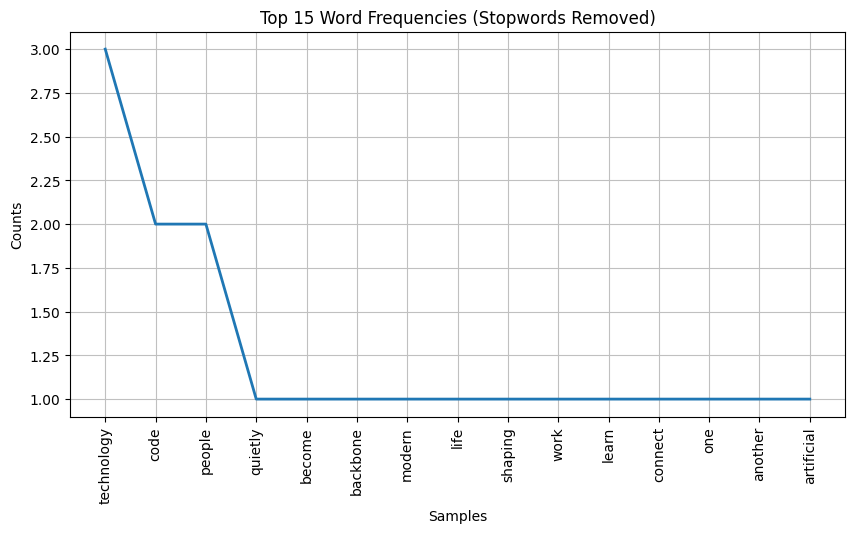

In [6]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

text = """Technology has quietly become the backbone of modern life, shaping how we work, learn, and connect with one another. Artificial intelligence, in particular, is transforming industries by automating repetitive tasks and uncovering patterns that humans often miss. Programmers write code that turns abstract ideas into tools used by millions of people every day. It's amazing how a few lines of well-written code can solve problems that once took teams of people weeks to finish. However, technology also raises important questions about privacy, fairness, and the future of human jobs. Learning to build and question technology at the same time is, in my opinion, the most valuable skill a student can develop today."""

# 1. Lowercase + remove punctuation using re
lower_text = text.lower()
clean_text = re.sub(r'[^\w\s]', '', lower_text)
print("Cleaned text:\n", clean_text, "\n")

# 2. Tokenization
sentences = sent_tokenize(text)          # use original text so sentence boundaries survive
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(f"{i}. {s}")

words = word_tokenize(clean_text)
print("\nWord tokens:", words)

# 3. split() vs word_tokenize() (on text WITH punctuation to show the difference)
split_tokens = lower_text.split()
nltk_tokens = word_tokenize(lower_text)

print("\nsplit() count        :", len(split_tokens))
print("word_tokenize() count:", len(nltk_tokens))
print("\nsplit() sample       :", split_tokens[:12])
print("word_tokenize sample :", nltk_tokens[:12])

# Tokens present in one result but not the other
print("\nOnly in split()        :", sorted(set(split_tokens) - set(nltk_tokens)))
print("Only in word_tokenize():", sorted(set(nltk_tokens) - set(split_tokens)))

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words if w not in stop_words]
print("\nBefore stopword removal:", len(words))
print("After stopword removal :", len(filtered_words))
print("Filtered words:", filtered_words)

# 5. Word frequency distribution (excluding stopwords)
freq = FreqDist(filtered_words)
print("\nTop 10 words:", freq.most_common(10))

plt.figure(figsize=(10, 5))
freq.plot(15, title="Top 15 Word Frequencies (Stopwords Removed)")
plt.show()

#### Q2. Using the same paragraph from Q1: 

##### 1. Extract all words with only alphabets using re.findall() 
##### 2. Remove stop words using NLTK’s stopword list 
##### 3. Perform stemming with PorterStemmer 
##### 4. Perform lemma za on with WordNetLemma zer 
##### 5. Compare the stemmed and lemma zed outputs and explain when you’d prefer one over the other. 

In [9]:

# Q2: Stemming and Lemmatization

import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
import pandas as pd

# Step 1: Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

print("Extracted Words:")
print(words)


# Step 2: Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nWords after Stopword Removal:")
print(filtered_words)


# Step 3: Perform Stemming using PorterStemmer
porter = PorterStemmer()

stemmed_words = [
    porter.stem(word) for word in filtered_words
]

print("\nStemmed Words:")
print(stemmed_words)


# Step 4: Perform Lemmatization using WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

lemmatized_words = [
    lemmatizer.lemmatize(word) for word in filtered_words
]

print("\nLemmatized Words:")
print(lemmatized_words)


# Step 5: Compare stemming and lemmatization
comparison = pd.DataFrame({
    "Original Word": filtered_words,
    "Stemmed Word": stemmed_words,
    "Lemmatized Word": lemmatized_words
})

print("\nComparison:")
print(comparison.to_string(index=False))


Extracted Words:
['technology', 'has', 'quietly', 'become', 'the', 'backbone', 'of', 'modern', 'life', 'shaping', 'how', 'we', 'work', 'learn', 'and', 'connect', 'with', 'one', 'another', 'artificial', 'intelligence', 'in', 'particular', 'is', 'transforming', 'industries', 'by', 'automating', 'repetitive', 'tasks', 'and', 'uncovering', 'patterns', 'that', 'humans', 'often', 'miss', 'programmers', 'write', 'code', 'that', 'turns', 'abstract', 'ideas', 'into', 'tools', 'used', 'by', 'millions', 'of', 'people', 'every', 'day', 'it', 's', 'amazing', 'how', 'a', 'few', 'lines', 'of', 'well', 'written', 'code', 'can', 'solve', 'problems', 'that', 'once', 'took', 'teams', 'of', 'people', 'weeks', 'to', 'finish', 'however', 'technology', 'also', 'raises', 'important', 'questions', 'about', 'privacy', 'fairness', 'and', 'the', 'future', 'of', 'human', 'jobs', 'learning', 'to', 'build', 'and', 'question', 'technology', 'at', 'the', 'same', 'time', 'is', 'in', 'my', 'opinion', 'the', 'most', 'val

#### Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews). 

##### 1. Use CountVectorizer to generate the Bag of Words representa on. 
##### 2. Use TfidfVectorizer to compute TF-IDF scores. 
##### 3. Print and interpret the top 3 keywords from each text using TF-IDF. 

In [10]:

# Q3: Bag of Words and TF-IDF

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Step 1: Create three short texts
texts = [
    "The laptop has a fast processor and excellent battery life.",
    "The smartphone has a great camera and long battery life.",
    "The laptop and smartphone both have excellent performance."
]

print("Original Texts:")
for i, text in enumerate(texts):
    print(f"Text {i+1}: {text}")


# Step 2: Bag of Words using CountVectorizer
count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(texts)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out()
)

print("\nBAG OF WORDS REPRESENTATION:")
print(bow_df)


# Step 3: Calculate TF-IDF scores
tfidf_vectorizer = TfidfVectorizer()

tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out()
)

print("\nTF-IDF REPRESENTATION:")
print(tfidf_df.round(3))


# Step 4: Print top 3 keywords from each text
print("\nTOP 3 KEYWORDS FROM EACH TEXT:")

for i in range(len(texts)):
    scores = tfidf_matrix[i].toarray().flatten()

    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nText {i+1}:")
    for index in top_indices:
        word = tfidf_vectorizer.get_feature_names_out()[index]
        print(word, ":", round(scores[index], 3))


Original Texts:
Text 1: The laptop has a fast processor and excellent battery life.
Text 2: The smartphone has a great camera and long battery life.
Text 3: The laptop and smartphone both have excellent performance.

BAG OF WORDS REPRESENTATION:
   and  battery  both  camera  excellent  fast  great  has  have  laptop  \
0    1        1     0       0          1     1      0    1     0       1   
1    1        1     0       1          0     0      1    1     0       0   
2    1        0     1       0          1     0      0    0     1       1   

   life  long  performance  processor  smartphone  the  
0     1     0            0          1           0    1  
1     1     1            0          0           1    1  
2     0     0            1          0           1    1  

TF-IDF REPRESENTATION:
     and  battery   both  camera  excellent   fast  great    has   have  \
0  0.250    0.322  0.000   0.000      0.322  0.423  0.000  0.322  0.000   
1  0.241    0.310  0.000   0.408      0.000  0.

#### Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain). 

##### 1. Preprocess and tokenize both texts. 
##### 2. Calculate: 
###### a. Jaccard Similarity using sets 
###### b. Cosine Similarity using TfidfVectorizer + cosine_similarity() 
###### c. Analyze which similarity metric gives be er insights in your case.

In [12]:

# Q4: Jaccard Similarity and Cosine Similarity

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Step 1: Write two texts about different technologies

text1 = """
Artificial Intelligence allows machines to learn from data.
AI helps computers solve problems and make decisions.
It is widely used in healthcare and education.
AI can automate tasks and improve efficiency.
"""

text2 = """
Blockchain is a technology used to store digital information.
It provides secure and transparent transactions.
Blockchain is widely used in cryptocurrency and finance.
It helps maintain records without a central authority.
"""

print("TEXT 1 - ARTIFICIAL INTELLIGENCE")
print(text1)

print("\nTEXT 2 - BLOCKCHAIN")
print(text2)


# Step 2: Preprocess and tokenize both texts

tokens1 = re.findall(r'\b[a-z]+\b', text1.lower())
tokens2 = re.findall(r'\b[a-z]+\b', text2.lower())

print("\nTokens of Text 1:")
print(tokens1)

print("\nTokens of Text 2:")
print(tokens2)


# Step 3: Calculate Jaccard Similarity using sets

set1 = set(tokens1)
set2 = set(tokens2)

intersection = set1.intersection(set2)
union = set1.union(set2)

jaccard = len(intersection) / len(union)

print("\nJaccard Similarity:", round(jaccard, 4))


# Step 4: Calculate Cosine Similarity using TF-IDF

documents = [text1, text2]

vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(documents)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])

print("Cosine Similarity:", round(cosine[0][0], 4))


# Step 5: Compare the results

print("\nSIMILARITY COMPARISON")
print("Jaccard Similarity:", round(jaccard, 4))
print("Cosine Similarity:", round(cosine[0][0], 4))


TEXT 1 - ARTIFICIAL INTELLIGENCE

Artificial Intelligence allows machines to learn from data.
AI helps computers solve problems and make decisions.
It is widely used in healthcare and education.
AI can automate tasks and improve efficiency.


TEXT 2 - BLOCKCHAIN

Blockchain is a technology used to store digital information.
It provides secure and transparent transactions.
Blockchain is widely used in cryptocurrency and finance.
It helps maintain records without a central authority.


Tokens of Text 1:
['artificial', 'intelligence', 'allows', 'machines', 'to', 'learn', 'from', 'data', 'ai', 'helps', 'computers', 'solve', 'problems', 'and', 'make', 'decisions', 'it', 'is', 'widely', 'used', 'in', 'healthcare', 'and', 'education', 'ai', 'can', 'automate', 'tasks', 'and', 'improve', 'efficiency']

Tokens of Text 2:
['blockchain', 'is', 'a', 'technology', 'used', 'to', 'store', 'digital', 'information', 'it', 'provides', 'secure', 'and', 'transparent', 'transactions', 'blockchain', 'is', 'w

##### Q5. Write a short review for a product or service.

##### 1. Use TextBlob or VADER to find polarity & subjec vity for each review. 
##### 2. Classify reviews into Posi ve / Nega ve / Neutral. 
##### 3. Create a word cloud using the wordcloud library for all posi ve reviews.

In [15]:
%pip install textblob wordcloud

   ---------------------------------------- 0.0/625.0 kB ? eta -:--:--
   ---------------------------------------- 625.0/625.0 kB 4.7 MB/s  0:00:00

   -------------------- ------------------- 1/2 [textblob]
   -------------------- ------------------- 1/2 [textblob]
   ---------------------------------------- 2/2 [textblob]

Note: you may need to restart the kernel to use updated packages.


SENTIMENT ANALYSIS
                                                     Review  Polarity  Subjectivity Sentiment
             The laptop is amazing and works very smoothly.  0.560000         0.775  Positive
The battery life is excellent and the performance is great.  0.900000         0.875  Positive
    The laptop is very slow and the battery drains quickly. -0.028333         0.510  Negative
    I am disappointed with the poor quality of this laptop. -0.575000         0.675  Negative
            The laptop is okay and has average performance.  0.175000         0.450  Positive

Positive Reviews:
The laptop is amazing and works very smoothly. The battery life is excellent and the performance is great. The laptop is okay and has average performance.


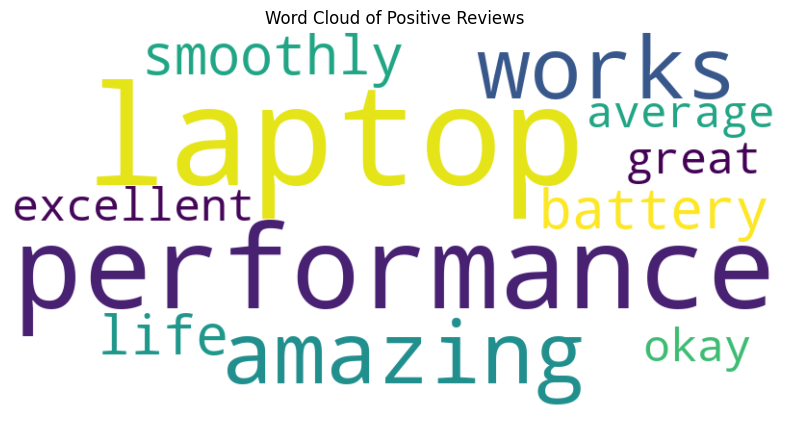

In [16]:

# Q5: Sentiment Analysis and Word Cloud

from textblob import TextBlob
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Step 1: Write product reviews
reviews = [
    "The laptop is amazing and works very smoothly.",
    "The battery life is excellent and the performance is great.",
    "The laptop is very slow and the battery drains quickly.",
    "I am disappointed with the poor quality of this laptop.",
    "The laptop is okay and has average performance."
]

# Step 2: Calculate polarity and subjectivity
results = []

for review in reviews:
    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    # Step 3: Classify sentiment
    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    results.append({
        "Review": review,
        "Polarity": polarity,
        "Subjectivity": subjectivity,
        "Sentiment": sentiment
    })

# Create DataFrame
df_reviews = pd.DataFrame(results)

print("SENTIMENT ANALYSIS")
print(df_reviews.to_string(index=False))


# Step 4: Collect all positive reviews
positive_reviews = df_reviews[
    df_reviews["Sentiment"] == "Positive"
]["Review"]

positive_text = " ".join(positive_reviews)

print("\nPositive Reviews:")
print(positive_text)


# Step 5: Generate Word Cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Positive Reviews")
plt.show()


#### Q6. Choose your own paragraph (~100 words) as training data. 

##### 1. Tokenize text using Tokenizer() from keras.preprocessing.text 
##### 2. Create input sequences and build a simple LSTM or Dense model 
##### 3. Train the model and generate 2–3 new lines of text star ng from any seed word you provide. 

In [17]:

# Q6: Text Generation using LSTM

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

# Step 1: Training paragraph (approximately 100 words)

text = """Technology plays an important role in our daily lives.
It helps students learn new things and improve their knowledge.
Artificial intelligence makes computers smarter and helps people solve problems.
Students use technology for education, communication and research.
Online learning provides access to information from anywhere.
Modern applications make everyday tasks easier and faster.
Technology also helps businesses improve their services.
However, people should use technology wisely and responsibly.
Learning new technologies helps students develop useful skills.
The future of technology will bring many exciting opportunities.
It will continue to change the way people learn and work."""

print("Training Text:")
print(text)


# Step 2: Tokenize the text

tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("\nTotal unique words:", total_words - 1)


# Step 3: Create input sequences

input_sequences = []

for sentence in text.lower().split('.'):
    token_list = tokenizer.texts_to_sequences([sentence])[0]

    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)


# Step 4: Pad sequences

max_sequence_len = max(len(seq) for seq in input_sequences)

input_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding='pre'
)

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = to_categorical(y, num_classes=total_words)

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)


# Step 5: Build the LSTM model

model = Sequential()

model.add(Embedding(total_words, 64))
model.add(LSTM(100))
model.add(Dense(total_words, activation='softmax'))

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


# Step 6: Train the model

model.fit(X, y, epochs=100, verbose=1)


# Step 7: Generate new text

seed_text = "technology helps students"

next_words = 30

for _ in range(next_words):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=max_sequence_len - 1,
        padding='pre'
    )

    predicted = model.predict(token_list, verbose=0)
    predicted_word_index = np.argmax(predicted, axis=1)[0]

    output_word = ""

    for word, index in tokenizer.word_index.items():
        if index == predicted_word_index:
            output_word = word
            break

    if output_word == "":
        break

    seed_text += " " + output_word

print("\nGENERATED TEXT:")
words = seed_text.split()

for i in range(0, len(words), 10):
    print(" ".join(words[i:i+10]))


Training Text:
Technology plays an important role in our daily lives.
It helps students learn new things and improve their knowledge.
Artificial intelligence makes computers smarter and helps people solve problems.
Students use technology for education, communication and research.
Online learning provides access to information from anywhere.
Modern applications make everyday tasks easier and faster.
Technology also helps businesses improve their services.
However, people should use technology wisely and responsibly.
Learning new technologies helps students develop useful skills.
The future of technology will bring many exciting opportunities.
It will continue to change the way people learn and work.

Total unique words: 70

Input shape: (85, 10)
Output shape: (85, 71)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.0235 - loss: 4.2634
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0824 - loss: 4.2532
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.0824 - loss: 4.2435
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.0941 - loss: 4.2320
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0941 - loss: 4.2133
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0941 - loss: 4.1888
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1059 - loss: 4.1471
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.0824 - loss: 4.0857
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.0824 - loss: 4.0585
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.0941 - loss: 4.0425
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.0824 - loss: 4.0147 
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.0824 - l